# Telecom Customer Churn Prediction with Ensemble Models
Random Forest and XGBoost classifiers for churn prediction on the Telco Customer Churn dataset. Categorical features are one-hot encoded, class imbalance is handled with both class weighting and SMOTE, models are tuned with stratified cross-validation, and performance is judged by ROC-AUC (target: above 0.80).

**Workflow:** load → clean `TotalCharges` → EDA → stratified split → preprocessing → imbalance strategies → cross-validated tuning → test evaluation (ROC, confusion matrix, threshold) → feature importance.

## 1. Imports and configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.4f}".format

## 2. Load the dataset

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data cleaning: `TotalCharges`
`TotalCharges` is stored as text because some rows contain blank strings. It is converted to numeric and the resulting nulls are inspected before deciding how to handle them.

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Null TotalCharges:", df["TotalCharges"].isnull().sum())
df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Null TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.5500,NaN,No
753,3115-CZMZD,0,20.2500,NaN,No
936,5709-LVOEQ,0,80.8500,NaN,No
1082,4367-NUYAO,0,25.7500,NaN,No
1340,1371-DWPAZ,0,56.0500,NaN,No
3331,7644-OMVMY,0,19.8500,NaN,No
3826,3213-VVOLG,0,25.3500,NaN,No
4380,2520-SGTTA,0,20.0000,NaN,No
5218,2923-ARZLG,0,19.7000,NaN,No
6670,4075-WKNIU,0,73.3500,NaN,No


Every null row has `tenure = 0`: these are customers who signed up but have not yet been billed. Their total charges are genuinely zero, so the nulls are filled with 0 instead of being dropped or imputed with a median. All 11 rows are kept.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0.0)

print("Remaining nulls:", int(df.isnull().sum().sum()))
print("Duplicate customer IDs:", int(df["customerID"].duplicated().sum()))
df = df.drop(columns="customerID")

Remaining nulls: 0
Duplicate customer IDs: 0


In [6]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
df["Churn"].value_counts().rename({0: "No churn", 1: "Churn"}).to_frame("customers").assign(share=lambda d: d["customers"] / len(df))

,customers,share
Churn,,
No churn,5174,0.7346
Churn,1869,0.2654


## 4. Exploratory data analysis

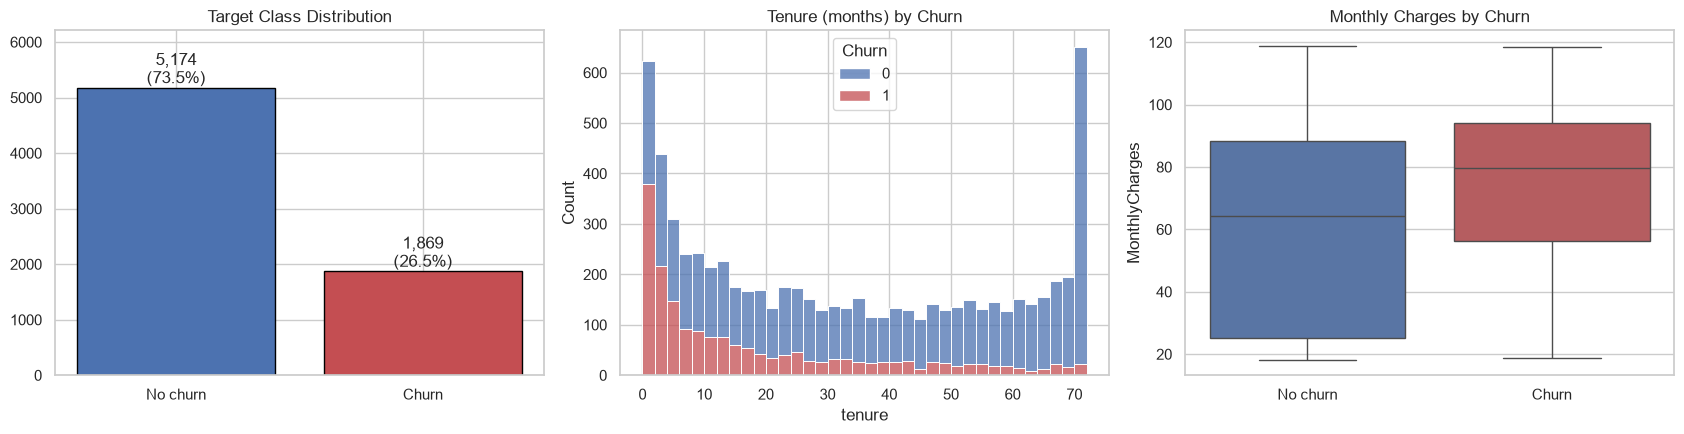

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df["Churn"].value_counts().sort_index()
axes[0].bar(["No churn", "Churn"], counts.values, color=["#4C72B0", "#C44E52"], edgecolor="black")
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
axes[0].set_title("Target Class Distribution")
axes[0].set_ylim(0, counts.max() * 1.2)

sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=36,
             palette={0: "#4C72B0", 1: "#C44E52"}, ax=axes[1])
axes[1].set_title("Tenure (months) by Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette=["#4C72B0", "#C44E52"], legend=False, ax=axes[2])
axes[2].set_xticklabels(["No churn", "Churn"])
axes[2].set_title("Monthly Charges by Churn")
axes[2].set_xlabel("")

plt.tight_layout()
plt.show()

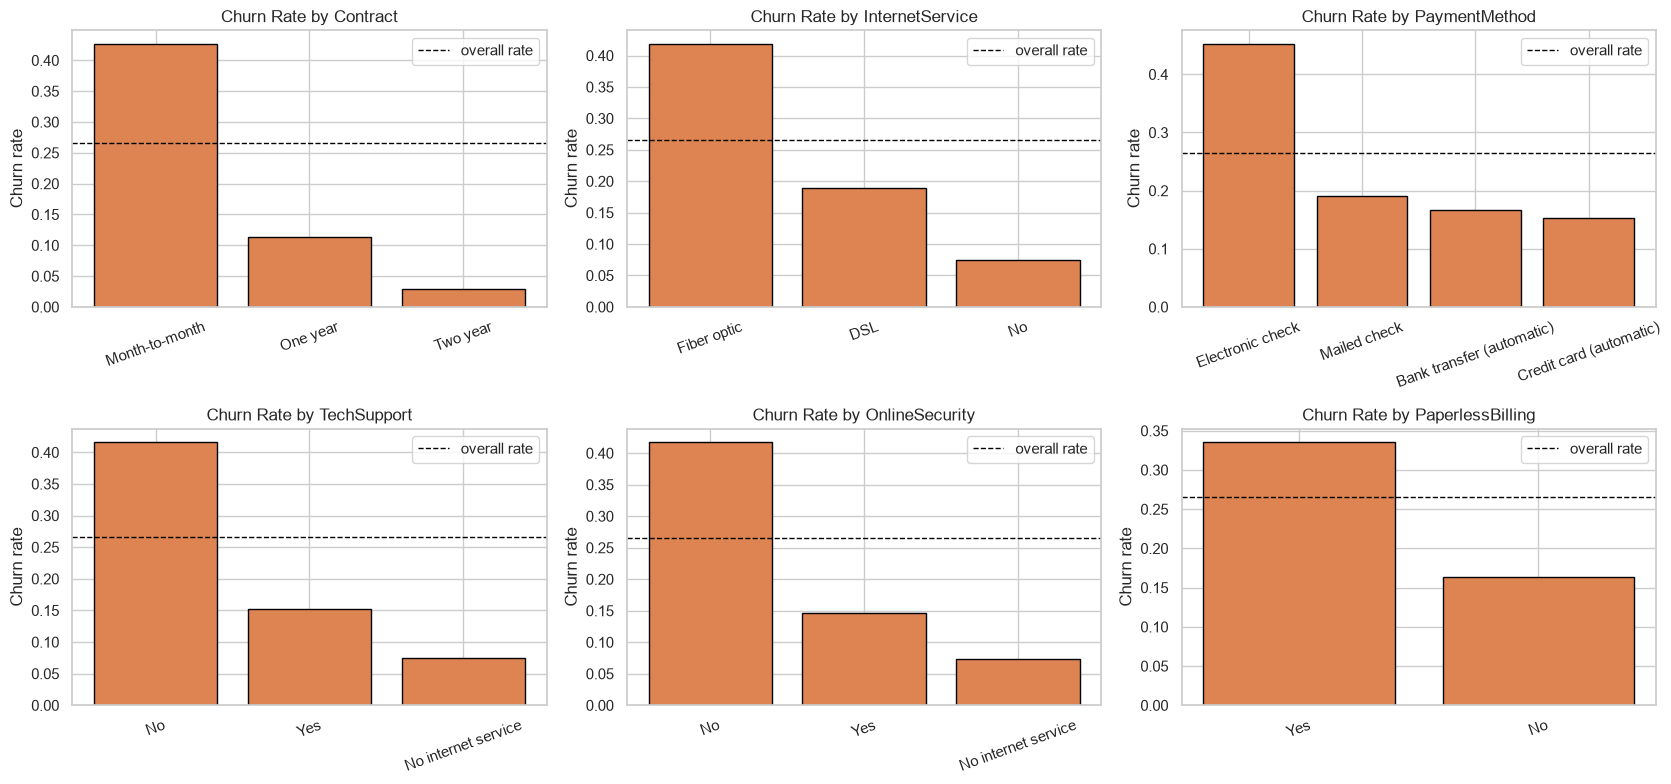

In [8]:
cat_cols_eda = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "PaperlessBilling"]

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, col in zip(axes.ravel(), cat_cols_eda):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color="#DD8452", edgecolor="black")
    ax.axhline(df["Churn"].mean(), color="black", linestyle="--", linewidth=1, label="overall rate")
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=20)
    ax.legend()
plt.tight_layout()
plt.show()

Churn is concentrated among month-to-month contracts, fiber-optic internet, electronic-check payment, customers without tech support or online security, and customers with short tenure. About 26.5% of customers churn, so the classes are imbalanced.

## 5. Train/test split and preprocessing
The split is stratified so both sets keep the same churn rate. Nothing below is fitted on the test set.

In [9]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Churn rate  train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train: 0.2654 | test: 0.2654


In [10]:
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

print(f"Categorical ({len(categorical_cols)}):", categorical_cols)
print(f"Numeric ({len(numeric_cols)}):", numeric_cols)

preprocessor = ColumnTransformer(
    [
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
        ("numeric", "passthrough", numeric_cols),
    ],
    verbose_feature_names_out=False,
)

Categorical (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


One-hot encoding turns each categorical column into binary indicator columns. Tree ensembles are insensitive to feature scale, so the numeric columns are passed through unscaled.

## 6. Handling class imbalance
Two strategies are compared for each algorithm:

- **Class weighting:** `class_weight="balanced_subsample"` for Random Forest and `scale_pos_weight = negatives / positives` for XGBoost. No data is created.
- **SMOTE:** synthetic minority-class samples are generated by interpolating between nearest neighbours. It runs inside the cross-validation pipeline, so only the training portion of each fold is resampled and validation folds stay untouched.

In [11]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos

X_train_enc = preprocessor.fit_transform(X_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_enc, y_train)

print(f"scale_pos_weight = {scale_pos_weight:.3f}")
print(f"Training class counts before SMOTE: {neg:,} no churn / {pos:,} churn")
print(f"Training class counts after SMOTE:  {(y_res == 0).sum():,} no churn / {(y_res == 1).sum():,} churn")

scale_pos_weight = 2.769
Training class counts before SMOTE: 4,139 no churn / 1,495 churn
Training class counts after SMOTE:  4,139 no churn / 4,139 churn


## 7. Cross-validated hyperparameter search
Four pipelines are tuned with `RandomizedSearchCV` using stratified 5-fold cross-validation scored by ROC-AUC. Model selection uses cross-validation scores only; the test set is held back for the final evaluation.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def rf_pipeline(use_smote):
    steps = [("prep", preprocessor)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    model = RandomForestClassifier(
        class_weight=None if use_smote else "balanced_subsample",
        n_jobs=1, random_state=RANDOM_STATE,
    )
    return ImbPipeline(steps + [("model", model)])


def xgb_pipeline(use_smote):
    steps = [("prep", preprocessor)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    model = XGBClassifier(
        scale_pos_weight=1.0 if use_smote else scale_pos_weight,
        eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=RANDOM_STATE,
    )
    return ImbPipeline(steps + [("model", model)])


rf_grid = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [None, 6, 8, 10, 14],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": ["sqrt", 0.3, 0.5],
}
xgb_grid = {
    "model__n_estimators": [150, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [1, 5, 10],
}

configs = {
    "Random Forest + class weights": (rf_pipeline(False), rf_grid),
    "Random Forest + SMOTE": (rf_pipeline(True), rf_grid),
    "XGBoost + scale_pos_weight": (xgb_pipeline(False), xgb_grid),
    "XGBoost + SMOTE": (xgb_pipeline(True), xgb_grid),
}

searches = {}
for name, (pipe, grid) in configs.items():
    searches[name] = RandomizedSearchCV(
        pipe, grid, n_iter=12, scoring="roc_auc", cv=cv,
        n_jobs=-1, random_state=RANDOM_STATE, refit=True,
    ).fit(X_train, y_train)
    print(f"{name:<32} best CV ROC-AUC = {searches[name].best_score_:.4f}")

Random Forest + class weights    best CV ROC-AUC = 0.8479
Random Forest + SMOTE            best CV ROC-AUC = 0.8430
XGBoost + scale_pos_weight       best CV ROC-AUC = 0.8494
XGBoost + SMOTE                  best CV ROC-AUC = 0.8477


In [13]:
rows = []
for name, search in searches.items():
    res = search.cv_results_
    best = search.best_index_
    rows.append({
        "Model": name,
        "CV ROC-AUC (mean)": res["mean_test_score"][best],
        "CV ROC-AUC (std)": res["std_test_score"][best],
        "Best parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })

cv_table = pd.DataFrame(rows).set_index("Model")
pd.set_option("display.max_colwidth", None)
cv_table

,CV ROC-AUC (mean),CV ROC-AUC (std),Best parameters
Model,,,
Random Forest + class weights,0.8479,0.0094,"{'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}"
Random Forest + SMOTE,0.8430,0.0097,"{'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}"
XGBoost + scale_pos_weight,0.8494,0.0118,"{'subsample': 0.85, 'reg_lambda': 10, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.6}"
XGBoost + SMOTE,0.8477,0.0122,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.8}"


In [14]:
best_rf_name = max([n for n in searches if n.startswith("Random Forest")], key=lambda n: searches[n].best_score_)
best_xgb_name = max([n for n in searches if n.startswith("XGBoost")], key=lambda n: searches[n].best_score_)
featured = {best_rf_name: searches[best_rf_name].best_estimator_, best_xgb_name: searches[best_xgb_name].best_estimator_}

print("Selected Random Forest:", best_rf_name)
print("Selected XGBoost:      ", best_xgb_name)

Selected Random Forest: Random Forest + class weights
Selected XGBoost:       XGBoost + scale_pos_weight


## 8. Test-set evaluation

In [15]:
def evaluate(model, X_te, y_te, threshold=0.5):
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_te, proba),
        "PR-AUC": average_precision_score(y_te, proba),
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
    }


test_results = pd.DataFrame({name: evaluate(s.best_estimator_, X_test, y_test) for name, s in searches.items()}).T
test_results["CV ROC-AUC"] = [searches[n].best_score_ for n in test_results.index]
test_results

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,CV ROC-AUC
Random Forest + class weights,0.8431,0.6495,0.7594,0.5318,0.7834,0.6335,0.8479
Random Forest + SMOTE,0.8366,0.6297,0.7708,0.5623,0.6150,0.5875,0.8430
XGBoost + scale_pos_weight,0.8465,0.6596,0.7459,0.5137,0.8021,0.6263,0.8494
XGBoost + SMOTE,0.8453,0.6641,0.7913,0.6064,0.6096,0.6080,0.8477


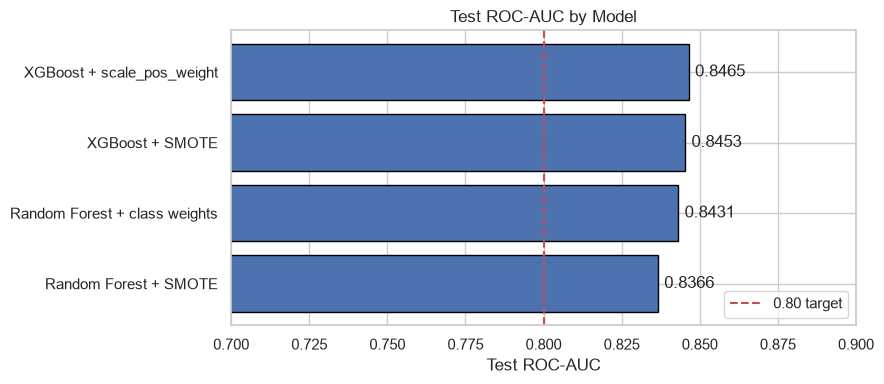

Models exceeding ROC-AUC 0.80 on the test set: 4 of 4


In [16]:
auc_view = test_results["ROC-AUC"].sort_values()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(auc_view.index, auc_view.values, color="#4C72B0", edgecolor="black")
ax.axvline(0.80, color="#C44E52", linestyle="--", linewidth=1.5, label="0.80 target")
ax.set_xlim(0.7, 0.9)
ax.set_xlabel("Test ROC-AUC")
ax.set_title("Test ROC-AUC by Model")
for bar, v in zip(bars, auc_view.values):
    ax.text(v + 0.002, bar.get_y() + bar.get_height() / 2, f"{v:.4f}", va="center")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Models exceeding ROC-AUC 0.80 on the test set:", int((test_results["ROC-AUC"] > 0.80).sum()), "of", len(test_results))

## 9. ROC curves

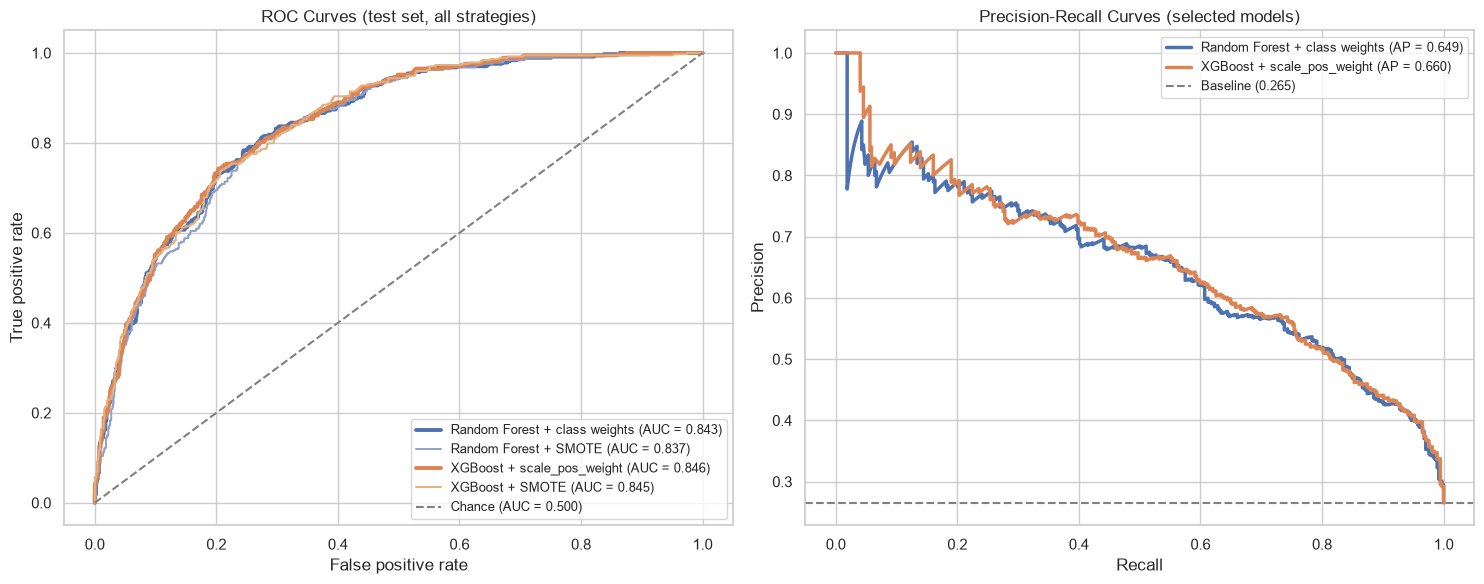

In [17]:
palette = {
    "Random Forest + class weights": "#4C72B0",
    "Random Forest + SMOTE": "#8DA0CB",
    "XGBoost + scale_pos_weight": "#DD8452",
    "XGBoost + SMOTE": "#E5B07F",
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, search in searches.items():
    proba = search.best_estimator_.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    lw = 2.8 if name in featured else 1.4
    axes[0].plot(fpr, tpr, color=palette[name], linewidth=lw, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Chance (AUC = 0.500)")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC Curves (test set, all strategies)")
axes[0].legend(loc="lower right", fontsize=9)

for name, model in featured.items():
    proba = model.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(recall, precision, color=palette[name], linewidth=2.5,
                 label=f"{name} (AP = {average_precision_score(y_test, proba):.3f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves (selected models)")
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.show()

## 10. Confusion matrices and classification reports

In [18]:
for name, model in featured.items():
    proba = model.predict_proba(X_test)[:, 1]
    print("=" * 62)
    print(f"{name}  (threshold = 0.50)")
    print("=" * 62)
    print(classification_report(y_test, (proba >= 0.5).astype(int), target_names=["No churn", "Churn"], digits=3))

Random Forest + class weights  (threshold = 0.50)
              precision    recall  f1-score   support

    No churn      0.906     0.751     0.821      1035
       Churn      0.532     0.783     0.634       374

    accuracy                          0.759      1409
   macro avg      0.719     0.767     0.727      1409
weighted avg      0.806     0.759     0.771      1409

XGBoost + scale_pos_weight  (threshold = 0.50)
              precision    recall  f1-score   support

    No churn      0.910     0.726     0.808      1035
       Churn      0.514     0.802     0.626       374

    accuracy                          0.746      1409
   macro avg      0.712     0.764     0.717      1409
weighted avg      0.805     0.746     0.759      1409



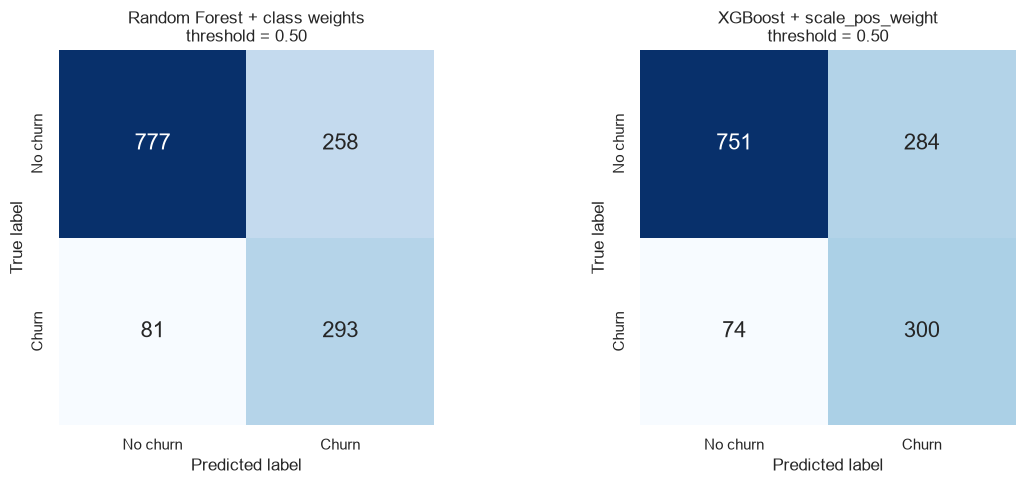

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, featured.items()):
    pred = (model.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"],
                annot_kws={"size": 16}, ax=ax)
    ax.set_title(f"{name}\nthreshold = 0.50")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 11. Decision threshold tuning
A 0.50 cutoff is not necessarily the best operating point for an imbalanced problem. The cutoff that maximizes F1 is chosen using out-of-fold predictions on the training set only, then applied once to the test set.

In [20]:
thresholds = {}
for name, model in featured.items():
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    precision, recall, cuts = precision_recall_curve(y_train, oof)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    thresholds[name] = cuts[np.argmax(f1)]
    print(f"{name:<32} F1-optimal threshold (train OOF) = {thresholds[name]:.3f}")

comparison = {}
for name, model in featured.items():
    comparison[(name, "threshold 0.50")] = evaluate(model, X_test, y_test, 0.5)
    comparison[(name, f"threshold {thresholds[name]:.2f}")] = evaluate(model, X_test, y_test, thresholds[name])

pd.DataFrame(comparison).T.drop(columns=["ROC-AUC", "PR-AUC"])

Random Forest + class weights    F1-optimal threshold (train OOF) = 0.517
XGBoost + scale_pos_weight       F1-optimal threshold (train OOF) = 0.565


Accuracy  Precision  Recall  \
Random Forest + class weights threshold 0.50    0.7594     0.5318  0.7834   
                              threshold 0.52    0.7615     0.5357  0.7620   
XGBoost + scale_pos_weight    threshold 0.50    0.7459     0.5137  0.8021   
                              threshold 0.57    0.7757     0.5573  0.7540   

                                                 F1  
Random Forest + class weights threshold 0.50 0.6335  
                              threshold 0.52 0.6291  
XGBoost + scale_pos_weight    threshold 0.50 0.6263  
                              threshold 0.57 0.6409

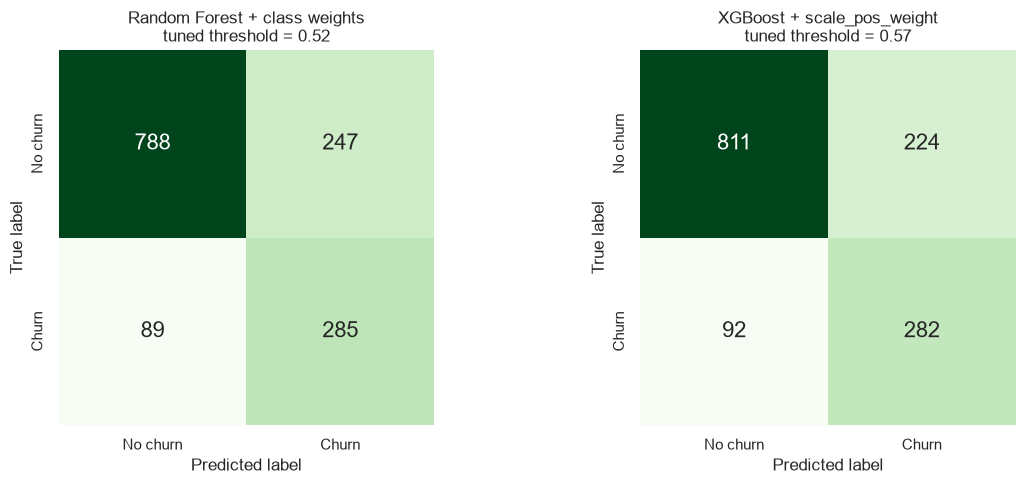

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, model) in zip(axes, featured.items()):
    pred = (model.predict_proba(X_test)[:, 1] >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, square=True,
                xticklabels=["No churn", "Churn"], yticklabels=["No churn", "Churn"],
                annot_kws={"size": 16}, ax=ax)
    ax.set_title(f"{name}\ntuned threshold = {thresholds[name]:.2f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

## 12. Feature importance

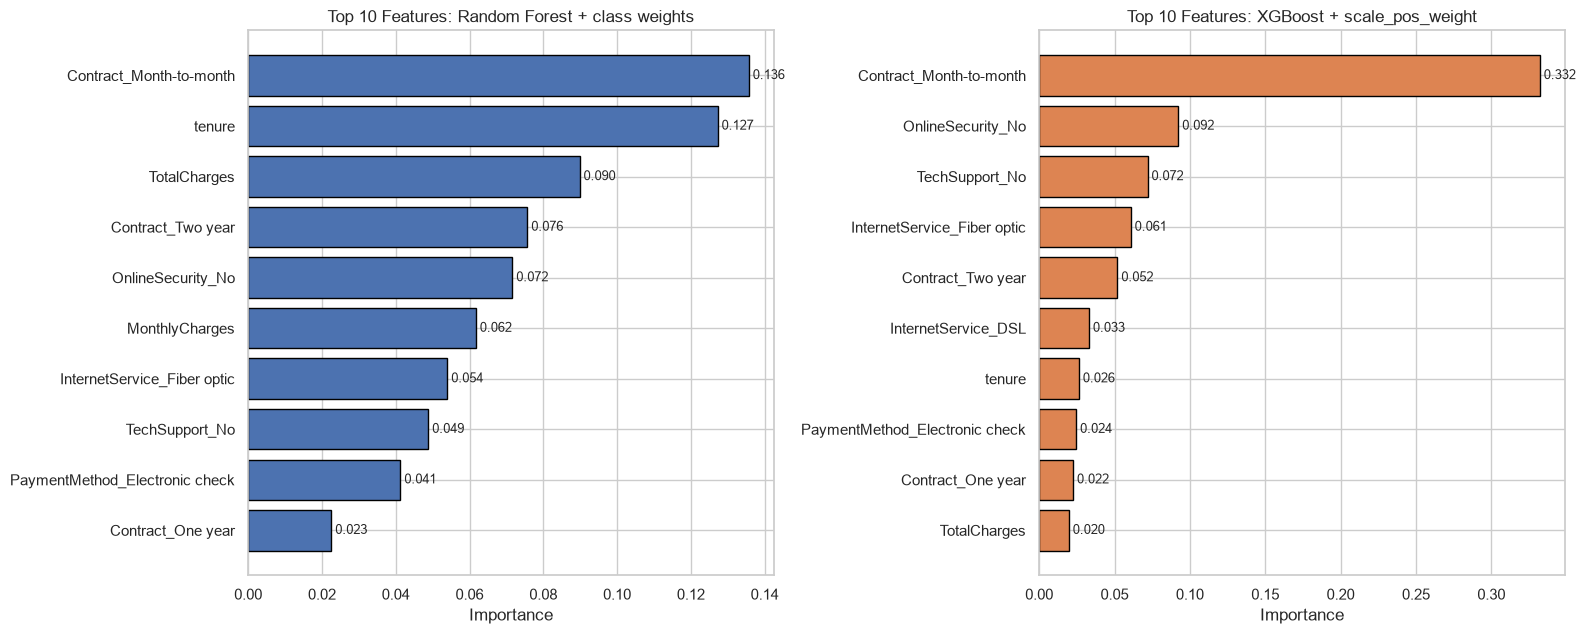

In [22]:
def feature_importance_frame(pipeline):
    names = pipeline.named_steps["prep"].get_feature_names_out()
    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
    return pd.Series(values, index=names).sort_values(ascending=False)


importances = {name: feature_importance_frame(model) for name, model in featured.items()}

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (name, imp), color in zip(axes, importances.items(), ["#4C72B0", "#DD8452"]):
    top = imp.head(10).iloc[::-1]
    ax.barh(top.index, top.values, color=color, edgecolor="black")
    ax.set_title(f"Top 10 Features: {name}")
    ax.set_xlabel("Importance")
    for i, v in enumerate(top.values):
        ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

In [23]:
pd.DataFrame({name: imp.head(10).index.tolist() for name, imp in importances.items()}, index=range(1, 11)).rename_axis("rank")

,Random Forest + class weights,XGBoost + scale_pos_weight
rank,,
1,Contract_Month-to-month,Contract_Month-to-month
2,tenure,OnlineSecurity_No
3,TotalCharges,TechSupport_No
4,Contract_Two year,InternetService_Fiber optic
5,OnlineSecurity_No,Contract_Two year
6,MonthlyCharges,InternetService_DSL
7,InternetService_Fiber optic,tenure
8,TechSupport_No,PaymentMethod_Electronic check
9,PaymentMethod_Electronic check,Contract_One year


Built-in importances (impurity-based for Random Forest, gain-based for XGBoost) can favor continuous columns with many split points, such as `TotalCharges` and `MonthlyCharges`. Permutation importance is a check that measures how much test ROC-AUC drops when a raw column is shuffled, which also groups the one-hot columns of each categorical feature back together.

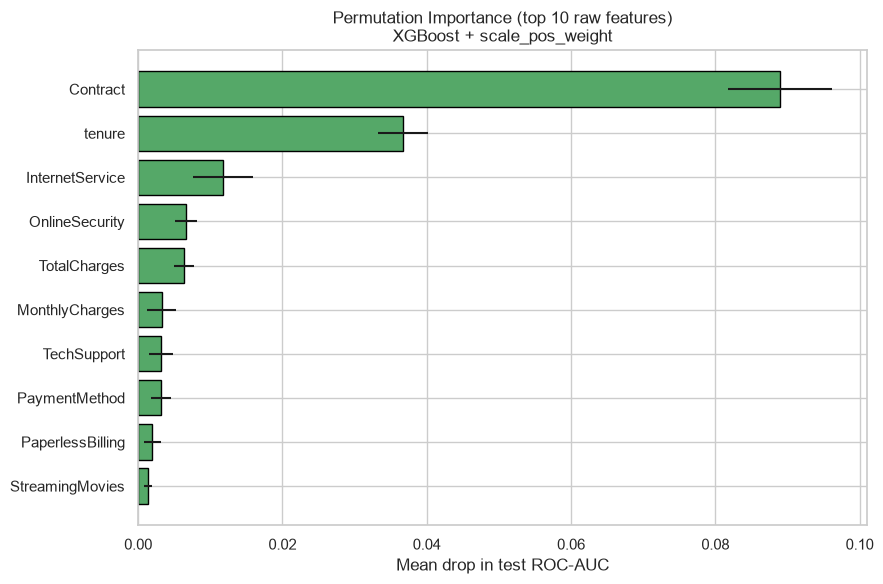

In [24]:
best_overall = test_results["CV ROC-AUC"].idxmax()
perm = permutation_importance(
    searches[best_overall].best_estimator_, X_test, y_test,
    scoring="roc_auc", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1,
)
perm_series = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
perm_std = pd.Series(perm.importances_std, index=X_test.columns).reindex(perm_series.index)

top = perm_series.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values, xerr=perm_std.reindex(top.index).values, color="#55A868", edgecolor="black")
ax.set_title(f"Permutation Importance (top 10 raw features)\n{best_overall}")
ax.set_xlabel("Mean drop in test ROC-AUC")
plt.tight_layout()
plt.show()

## 13. Summary

In [25]:
best_test = test_results["ROC-AUC"].idxmax()
print(f"Best CV model:        {test_results['CV ROC-AUC'].idxmax()} ({test_results['CV ROC-AUC'].max():.4f})")
print(f"Best test ROC-AUC:    {best_test} ({test_results.loc[best_test, 'ROC-AUC']:.4f})")
print(f"ROC-AUC > 0.80 target met by all models: {bool((test_results['ROC-AUC'] > 0.80).all())}")
test_results[["CV ROC-AUC", "ROC-AUC", "PR-AUC", "Accuracy", "Precision", "Recall", "F1"]]

Best CV model:        XGBoost + scale_pos_weight (0.8494)
Best test ROC-AUC:    XGBoost + scale_pos_weight (0.8465)
ROC-AUC > 0.80 target met by all models: True


,CV ROC-AUC,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Random Forest + class weights,0.8479,0.8431,0.6495,0.7594,0.5318,0.7834,0.6335
Random Forest + SMOTE,0.8430,0.8366,0.6297,0.7708,0.5623,0.6150,0.5875
XGBoost + scale_pos_weight,0.8494,0.8465,0.6596,0.7459,0.5137,0.8021,0.6263
XGBoost + SMOTE,0.8477,0.8453,0.6641,0.7913,0.6064,0.6096,0.6080


### Findings

- **The ROC-AUC target is met.** All four tuned models exceed 0.80 on the held-out test set, with test ROC-AUC between 0.836 and 0.847. Cross-validated AUC is 0.843 to 0.850, so the test result is consistent with the validation estimate.
- **XGBoost is slightly ahead, but the gap is small.** XGBoost with `scale_pos_weight` has the best CV ROC-AUC (0.8495) and test ROC-AUC (0.8470), against 0.8479 and 0.8431 for Random Forest with class weights. The CV standard deviations (about 0.01) are larger than these differences, so the two algorithms are effectively comparable.
- **Class weighting matched or beat SMOTE.** For both algorithms the class-weighted version had a higher CV and test ROC-AUC than the SMOTE version, and it does so without generating synthetic rows. The two strategies differ mainly in where they land at the default 0.50 cutoff: class weighting favors recall (about 0.78 to 0.80) at the cost of precision (about 0.51 to 0.53), while SMOTE gives a more balanced 0.61 for XGBoost.
- **The cutoff matters more than the model.** At 0.50 the selected models catch roughly 78% to 80% of churners but flag many loyal customers (precision around 0.5). Moving the cutoff to the F1-optimal value, chosen on out-of-fold training predictions, trades a little recall for precision and leaves F1 almost unchanged (about 0.63). The right cutoff depends on the relative cost of a missed churner versus an unnecessary retention offer.
- **Top drivers are consistent across models.** Month-to-month contracts and short tenure come out on top. Fiber-optic internet, electronic-check payment, and the absence of online security or tech support also raise churn risk, while two-year contracts lower it. Built-in importances rank `tenure` only 8th for XGBoost, but permutation importance puts `Contract` and `tenure` far ahead of everything else (each costing about 0.06 AUC when shuffled). The built-in ranking splits the signal across overlapping one-hot columns and correlated features, which is why both views are reported.
- **Limitations.** Accuracy at 0.50 (about 0.74 to 0.79) is not a useful headline metric because the classes are imbalanced. The dataset has no time dimension, so these results describe a random split and not a forward-in-time forecast.